In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname or "pingo" in hostname or "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/final/"




INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)
# sys.path.append(os.path.join(UTILS_DIR, 'pymascdb'))
os.chdir(os.path.join(UTILS_DIR, 'pymascdb'))

# # make figure directory to put in reflectivity processed data
# try:
#     new_dir = pathlib.Path(FIG_DIR)
#     new_dir.mkdir(parents=True, exist_ok=True)
# except OSError:
#     pass

ivan.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

In [3]:
from imports_mascdb import (masc, np, pd, cm, xr, glob, set_context, plt, mdates, time, datetime, BoundaryNorm, LinearSegmentedColormap, )

In [4]:
import functions_mascdb as fct
from mascdb.utils_img import (xri_zoom)

In [5]:
# plot cosmetics
set_context('paper', rc={"lines.linewidth": 2}, font_scale=1.5, )

In [6]:
# reload imports
%load_ext autoreload
%autoreload 2

In [7]:
masc_in = os.path.join(INPUT_DATA_DIR, 'MASC_DB')
### Create MASC_DB instance 
mascdb = masc.MASC_DB(dir_path=masc_in)

In [8]:
campaign23 = mascdb.select_campaign('Norway-2023')


In [9]:
file_paths = sorted(glob(os.path.join(OUTPUT_DATA_DIR, f'ANX_obs_EM_0_0.0', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_ANX_2023.nc'))) 

datasets = [xr.open_dataset(file_path) for file_path in file_paths]
ds = xr.combine_by_coords(datasets, compat='override')

ds = ds[['snowflake_class_name_60', 'shifted_time_end', 'start_time' , 'delta_h', 'rate_mm_h', 
# 'air_temperature', 
'snowflake_class_name_70', 'snowflake_class_name_80', "S_0_0.0_400_mm_h"]].to_dataframe()
indexes_to_exclude = ds[ds['snowflake_class_name_60'] == 'pristine'].index
ds = ds.loc[~ds.index.isin(indexes_to_exclude)].dropna()

In [10]:
0.033333*60

1.99998

In [11]:
ds_23 = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, f'ANX_obs_EM_0_0.0', f'10min_filled_obs_hatpro_airport_WD_WS_T_ANX_2023*.nc'))))#[['Ze', 'W', 'height', 'air_temperature', 'precipitation', 'wind_direction', 'wind_speed', 'Matrosov_a_400', 'Bracci_a_400','Pu_g_400','Ze_400m']]
ds_23 = ds_23.rename_vars({'precipitation':'Geonor'})

In [12]:
# -----------------------------
# 1) case windows
# -----------------------------
date_g = '20230308'
day_start_g = pd.Timestamp(f"{date_g} 17:00:00")
day_end_g = day_start_g + pd.Timedelta(hours=0, minutes=59)
ds_g_case = ds_23.sel(time=slice(day_start_g-pd.Timedelta(minutes=10), day_end_g))
df_g_case = ds.loc[day_start_g: day_end_g]

precip_g = ds[['rate_mm_h', 'delta_h', 'start_time']].loc[day_start_g : day_end_g]

# -----
date_a = '20230223'

day_start_a = pd.Timestamp(f"{date_a} 07:00:00")
day_end_a = day_start_a + pd.Timedelta(hours=0, minutes=59)
ds_a_case = ds_23.sel(time=slice(day_start_a-pd.Timedelta(minutes=10), day_end_a))
df_a_case = ds.loc[day_start_a: day_end_a]

precip_a = ds[['rate_mm_h', 'delta_h', 'start_time']].loc[day_start_a: day_end_a]

# -----
date_devi = '20230311'

day_start_devi = pd.Timestamp(f"{date_devi} 00:00:00")
day_end_devi = day_start_devi + pd.Timedelta(hours=24, )
ds_devi_case = ds_23.sel(time=slice(day_start_devi-pd.Timedelta(minutes=10), day_end_devi))
df_devi_case = ds.loc[day_start_devi: day_end_devi]

precip_devi = ds[['rate_mm_h', 'delta_h', 'start_time']].loc[day_start_devi: day_end_devi]

In [13]:
# -----------------------------
# 2) Apply rate + duration filter
# -----------------------------
graupel_events = fct.filter_events(df_g_case)
aggregate_events = fct.filter_events(df_a_case)
# deviation_events = fct.filter_events(df_devi_case)
deviation_events = df_devi_case.copy()

In [14]:
# -----------------------------
# 3) Restrict to class
# -----------------------------
graupel_events = graupel_events[graupel_events['snowflake_class_name_60'] == 'graupel']
aggregate_events = aggregate_events[aggregate_events['snowflake_class_name_60'] == 'aggregate']


In [15]:
graupel_events.loc[graupel_events['rate_mm_h'].idxmax()]

snowflake_class_name_60                graupel
shifted_time_end           2023-03-08 17:51:00
start_time                 2023-03-08 17:53:00
delta_h                                   0.05
rate_mm_h                                2.528
snowflake_class_name_70                graupel
snowflake_class_name_80                graupel
S_0_0.0_400_mm_h                           inf
Name: 2023-03-08 17:56:00, dtype: object

In [16]:
aggregate_events.loc[aggregate_events['rate_mm_h'].idxmax()]

snowflake_class_name_60              aggregate
shifted_time_end           2023-02-23 07:04:00
start_time                 2023-02-23 07:08:00
delta_h                                   0.05
rate_mm_h                                2.234
snowflake_class_name_70              aggregate
snowflake_class_name_80              aggregate
S_0_0.0_400_mm_h                           inf
Name: 2023-02-23 07:11:00, dtype: object

In [17]:
deviation_events.loc[deviation_events['rate_mm_h'].idxmax()]

snowflake_class_name_60                graupel
shifted_time_end           2023-03-11 23:26:00
start_time                 2023-03-11 23:28:00
delta_h                               0.016667
rate_mm_h                                15.84
snowflake_class_name_70                  mixed
snowflake_class_name_80                  mixed
S_0_0.0_400_mm_h                           inf
Name: 2023-03-11 23:29:00, dtype: object

In [18]:
# -----------------------------
# Quality filter
# -----------------------------
quality_mask = campaign23.triplet['flake_quality_xhi'] > 8.5
masc_quality = campaign23.isel(quality_mask)

# -----------------------------
# Match flakes to event timestamps
# -----------------------------
# masc_quality.da['flake_id']

In [19]:
cam1 = masc_quality.triplet.copy()
# 2) ensure datetime column is datetime dtype
cam1['datetime'] = pd.to_datetime(cam1['datetime'])
cam1 = cam1.sort_values('datetime')

# # for end_time, start_time in graupel_events['start_time'].items():
# #     t0 = start_time
# #     t1 = end_time - pd.Timedelta(seconds=1)
# #     if graupel_events.loc[graupel_events['rate_mm_h'].idxmax(), 'start_time'] == t0:
# #         # print(graupel.loc[t0:t1])
# #         mask = (
# #         (cam1['datetime'] >= t0) &
# #         (cam1['datetime'] <= t1)
# #     )
# #         if cam1.index.name == "flake_id":
# #             flake_ids_graupel = cam1.index[mask].tolist()
# #         elif 'flake_id' in cam1.columns:
# #             flake_ids_graupel = cam1.loc[mask, 'flake_id'].tolist()
# #         else:
# #             raise RuntimeError("Can't find flake_id as index or column in cam1")


# # if len(flake_ids_graupel) == 0:
# #     print("No flakes found in that time window.")
# # else:
# #     # 5) subset the MASC_DB using sel
# #     graupel_db = campaign23.sel(flake_ids=flake_ids_graupel)   # returns a MASC_DB instance. 

# # 1. restrict to time window
# cam_subset = cam1[
#     (cam1['datetime'] >= day_start_g) &
#     (cam1['datetime'] <= day_end_g)
# ].copy()

# # 2. sort by time
# cam_subset = cam_subset.sort_values('datetime')

# # 3. split into 16 time bins
# n_samples = 16
# bins = np.linspace(0, len(cam_subset), n_samples + 1).astype(int)

# selected_ids = []

# for i in range(n_samples):
#     subset_bin = cam_subset.iloc[bins[i]:bins[i+1]]
    
#     if len(subset_bin) == 0:
#         continue
    
#     # pick best quality within this time slice
#     best_idx = subset_bin['flake_quality_xhi'].idxmax()
#     selected_ids.append(best_idx)

# # 4. subset DB
# graupel_db = campaign23.sel(flake_ids=selected_ids)

In [20]:
day_start_a, day_end_a

(Timestamp('2023-02-23 07:00:00'), Timestamp('2023-02-23 07:59:00'))

In [21]:


# # for end_time, start_time in aggregate_events['start_time'].items():
# #     t0 = start_time
# #     t1 = end_time - pd.Timedelta(seconds=1)
# #     if aggregate_events.loc[aggregate_events['rate_mm_h'].idxmax(), 'start_time'] == t0:
# #         # print(graupel.loc[t0:t1])
# #         mask = (
# #         (cam1['datetime'] >= t0) &
# #         (cam1['datetime'] <= t1)
# #     )
# #         if cam1.index.name == "flake_id":
# #             flake_ids_aggregate = cam1.index[mask].tolist()
# #         elif 'flake_id' in cam1.columns:
# #             flake_ids_aggregate = cam1.loc[mask, 'flake_id'].tolist()
# #         else:
# #             raise RuntimeError("Can't find flake_id as index or column in cam1")


# # if len(flake_ids_aggregate) == 0:
# #     print("No flakes found in that time window.")
# # else:
# #     # 5) subset the MASC_DB using sel
# #     aggregate_db = campaign23.sel(flake_ids=flake_ids_aggregate)   # returns a MASC_DB instance. 


# # 1. restrict to time window
# cam_subset = cam1[
#     (cam1['datetime'] >= day_start_a) &
#     (cam1['datetime'] <= day_end_a)
# ].copy()

# # 2. sort by time
# cam_subset = cam_subset.sort_values('datetime')

# # 3. split into 16 time bins
# n_samples = 16
# bins = np.linspace(0, len(cam_subset), n_samples + 1).astype(int)

# selected_ids = []

# for i in range(n_samples):
#     subset_bin = cam_subset.iloc[bins[i]:bins[i+1]]
    
#     if len(subset_bin) == 0:
#         continue
    
#     # pick best quality within this time slice
#     best_idx = subset_bin['flake_quality_xhi'].idxmax()
#     selected_ids.append(best_idx)

# # 4. subset DB
# aggregate_db = campaign23.sel(flake_ids=selected_ids)

In [22]:
# # mask = (
# #         (cam1['datetime'] >= '2023-03-11 16:00:00') &
# #         (cam1['datetime'] <= '2023-03-11 16:30:00')
# #     )
# # if cam1.index.name == "flake_id":
# #             flake_ids_deviation = cam1.index[mask].tolist()
# # elif 'flake_id' in cam1.columns:
# #             flake_ids_deviation = cam1.loc[mask, 'flake_id'].tolist()
# # else:
# #             raise RuntimeError("Can't find flake_id as index or column in cam1")

# # if len(flake_ids_deviation) == 0:
# #     print("No flakes found in that time window.")
# # else:
# #     # 5) subset the MASC_DB using sel
# #     deviation_db = campaign23.sel(flake_ids=flake_ids_deviation)   # returns a MASC_DB instance. 

# # 1. restrict to time window
# cam_subset = cam1[
#     (cam1['datetime'] >= day_start_devi) &
#     (cam1['datetime'] <= day_end_devi)
# ].copy()

# # 2. sort by time
# cam_subset = cam_subset.sort_values('datetime')

# # 3. split into 16 time bins
# n_samples = 16
# bins = np.linspace(0, len(cam_subset), n_samples + 1).astype(int)

# selected_ids = []

# for i in range(n_samples):
#     subset_bin = cam_subset.iloc[bins[i]:bins[i+1]]
    
#     if len(subset_bin) == 0:
#         continue
    
#     # pick best quality within this time slice
#     best_idx = subset_bin['flake_quality_xhi'].idxmax()
#     selected_ids.append(best_idx)

# # 4. subset DB
# deviation_db = campaign23.sel(flake_ids=selected_ids)

In [23]:
def select_representative_flakes(df_events, cam1, campaign, n_total=16):
    
    # rank events by precipitation intensity
    df_events = df_events.copy()
    df_events['event_rank'] = df_events['rate_mm_h'].rank(ascending=False, method='first')
    df_events = df_events.sort_values('event_rank')
    
    n_events = len(df_events)
    
    selected_ids = []
    
    if n_events <= n_total:
        # take multiple flakes per event
        n_per_event = int(np.ceil(n_total / n_events))
    else:
        # take only top n_total events
        df_events = df_events.iloc[:n_total]
        n_per_event = 1
    
    for _, row in df_events.iterrows():
        t0 = row['start_time']
        t1 = row.name  # end_time (index)
        
        mask = (
            (cam1['datetime'] >= t0) &
            (cam1['datetime'] <= t1)
        )
        subset = cam1.loc[mask]
        
        if len(subset) == 0:
            continue
        
        # pick best quality flakes in this event
        best = subset['flake_quality_xhi'].nlargest(n_per_event)
        selected_ids.extend(best.index.tolist())
    
    # ensure exactly n_total
    selected_ids = selected_ids[:n_total]
    
    return campaign.sel(flake_ids=selected_ids)

In [24]:
aggregate_db = select_representative_flakes(df_events=aggregate_events, cam1=cam1, campaign=campaign23, n_total=16)
graupel_db = select_representative_flakes(df_events=graupel_events, cam1=cam1, campaign=campaign23, n_total=16)
deviation_db = select_representative_flakes(df_events=deviation_events, cam1=cam1, campaign=campaign23, n_total=16)

In [25]:
best_ids_g = fct.select_flakes_best_quality(graupel_db, 16)
best_ids_a = fct.select_flakes_best_quality(aggregate_db, 16)
best_ids_devi = fct.select_flakes_best_quality(deviation_db, 16)

In [26]:
# Subset full DB with those IDs
graupel_best = graupel_db.sel(flake_ids=best_ids_g)
aggregate_best = aggregate_db.sel(flake_ids=best_ids_a)
deviation_best = deviation_db.sel(flake_ids=best_ids_devi)

In [27]:
indices = list(range(16))
da = aggregate_best.da.isel(cam_id=1, flake_id=indices)
da_zoomed_a = xri_zoom(da, squared=True)

da = graupel_best.da.isel(cam_id=1, flake_id=indices)
da_zoomed_g = xri_zoom(da, squared=True)

da = deviation_best.da.isel(cam_id=1, flake_id = indices)
da_zoomed_devi = xri_zoom(da, squared=True)

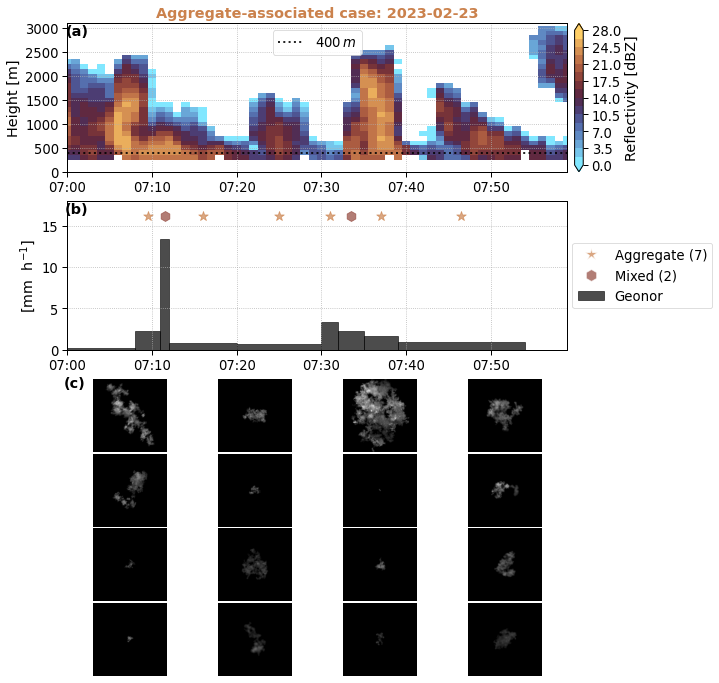

In [28]:
fig_a = fct.plt_case_figure(ds_a_case, df_a_case, precip_a, da_zoomed_a, day_start_a, day_end_a, case_name="Aggregate-associated case", case_color=fct.custom_colors['aggregate'], fig_label_start="c", )
plt.savefig(FIG_DIR + "fig05.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

In [29]:
ds_g_case['Ze'].mean().values

array(13.78668962)

In [30]:
precip_g['delta_h']*60

time
2023-03-08 17:01:00    5.0
2023-03-08 17:04:00    3.0
2023-03-08 17:06:00    2.0
2023-03-08 17:08:00    2.0
2023-03-08 17:11:00    3.0
2023-03-08 17:12:00    1.0
2023-03-08 17:13:00    1.0
2023-03-08 17:16:00    3.0
2023-03-08 17:18:00    2.0
2023-03-08 17:23:00    5.0
2023-03-08 17:32:00    9.0
2023-03-08 17:33:00    1.0
2023-03-08 17:35:00    2.0
2023-03-08 17:36:00    1.0
2023-03-08 17:39:00    3.0
2023-03-08 17:42:00    3.0
2023-03-08 17:44:00    2.0
2023-03-08 17:45:00    1.0
2023-03-08 17:53:00    8.0
2023-03-08 17:56:00    3.0
2023-03-08 17:58:00    1.0
2023-03-08 17:59:00    1.0
Name: delta_h, dtype: float64

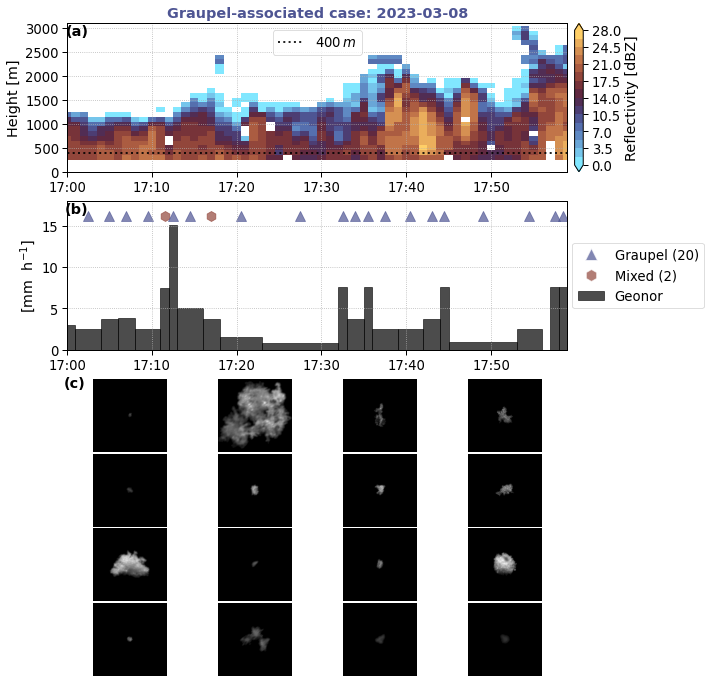

In [31]:
fig_a = fct.plt_case_figure(ds_g_case, df_g_case, precip_g, da_zoomed_g, day_start_g, day_end_g, case_name="Graupel-associated case", case_color=fct.custom_colors['graupel'], fig_label_start="c")
plt.savefig(FIG_DIR + "fig06.png", format='png', bbox_inches='tight', transparent=True,dpi=300)


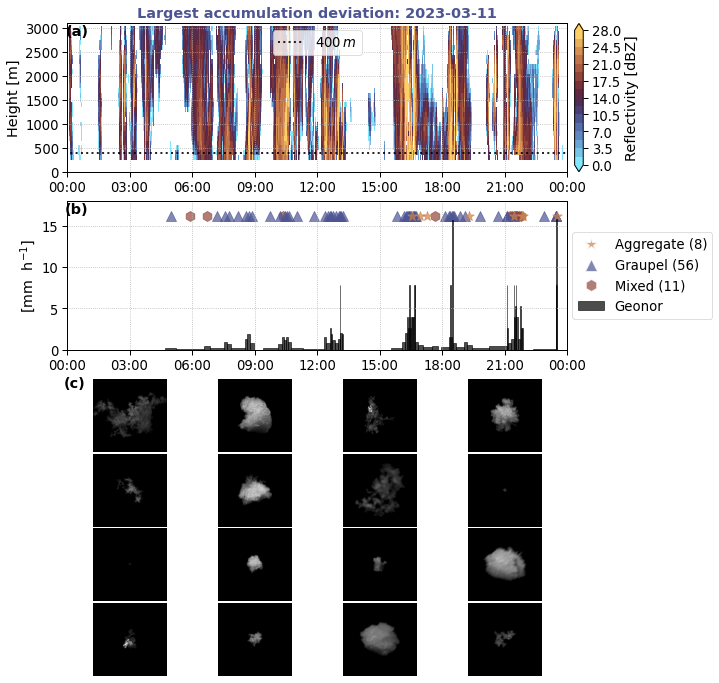

In [32]:
fig_devi = fct.plt_case_figure(ds_devi_case, df_devi_case, precip_devi, da_zoomed_devi, day_start_devi, day_end_devi, case_name="Largest accumulation deviation", case_color=fct.custom_colors['graupel'], fig_label_start="c", ylim=[0,18])
plt.savefig(FIG_DIR + "figA5.png", format='png', bbox_inches='tight', transparent=True,dpi=300)


In [33]:
row = df_g_case.iloc[0]   # pick one event

# Surface event window
t1_surface = row.name
t0_surface = row["start_time"]

# Shifted radar window (what you WANT)
t1_shifted = row["shifted_time_end"]
t0_shifted = t1_shifted - pd.to_timedelta(row["delta_h"], unit="h")

print("Surface window:", t0_surface, "→", t1_surface)
print("Radar window:  ", t0_shifted, "→", t1_shifted)

Z_shifted = ds_g_case["Ze_400m"].sel(time=slice(t0_shifted, t1_shifted))

Surface window: 2023-03-08 16:56:00 → 2023-03-08 17:01:00
Radar window:   2023-03-08 16:51:00.000001200 → 2023-03-08 16:56:00


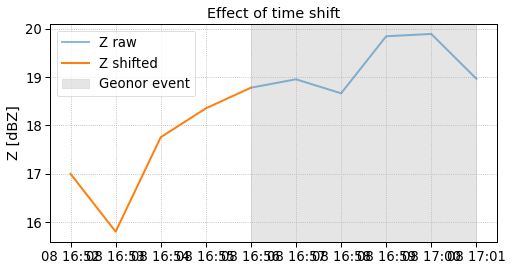

In [34]:
plt.figure(figsize=(8,4))

# raw (unshifted)
Z_raw = ds_g_case["Ze_400m"].sel(time=slice(t0_surface, t1_surface))
plt.plot(Z_raw["time"], Z_raw, label="Z raw", alpha=0.5)

# shifted
plt.plot(Z_shifted["time"], Z_shifted, label="Z shifted", linewidth=2)

plt.axvspan(t0_surface, t1_surface, color="grey", alpha=0.2, label="Geonor event")

plt.legend()
plt.ylabel("Z [dBZ]")
plt.title("Effect of time shift")
plt.grid(ls=":")
plt.show()

In [35]:
df_all = pd.concat([df_a_case, df_g_case], axis=0)
df_all = df_all.sort_index()


In [36]:

S_vals = []
Z_vals = []
event_labels = []

for _, row in df_all.iterrows():

    # surface event window
    t0_surface = row["start_time"]
    t1_surface = row.name  # end time (since your index is end time)

    # shifted radar window
    t1_shifted = row["shifted_time_end"]
    t0_shifted = t1_shifted - pd.Timedelta(row["delta_h"], unit="h")


    S = row["rate_mm_h"]
    sf_cls = row["snowflake_class_name_60"]

    # extract radar reflectivity during event
    Z_window = ds_23["Ze_400m"].sel(time=slice(t0_shifted, t1_shifted)).values
    # flatten and pair with constant S
    Z_window = Z_window[~np.isnan(Z_window)]

    S_vals.extend([S] * len(Z_window))
    Z_vals.extend(Z_window)
    event_labels.extend([sf_cls] * len(Z_window))

S_vals = np.array(S_vals)
Z_vals = np.array(Z_vals)
event_labels = np.array(event_labels)

In [37]:
markers_dict = {
    "aggregate": "*",
    "graupel": "^",
    "mixed": "h"
}

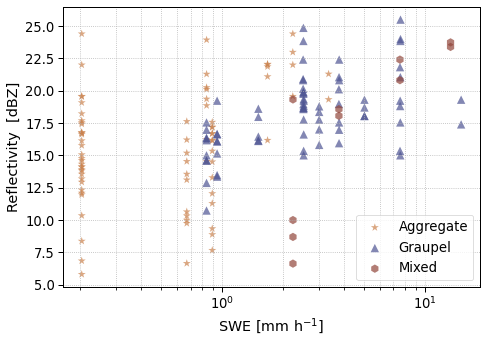

In [38]:

df_plot = pd.DataFrame({
    "S": S_vals,
    "Z": Z_vals,
    "class": event_labels
})



fig, ax = plt.subplots(1, 1, figsize=(7,5), sharex=True, sharey=True, constrained_layout=True)


for c in ["aggregate", "graupel", "mixed"]:

    sub = df_plot[df_plot["class"] == c]

    if len(sub) == 0:
        continue

    ax.scatter(
        sub["S"],
        sub["Z"],
        label=f"{c.title()}",
        alpha=0.7,
        s=70,
        color=fct.custom_colors[c],
        marker=markers_dict[c],
        edgecolors="none"
    )

    

ax.set_xlabel("SWE [mm h$^{-1}$]")
ax.set_ylabel("Reflectivity  [dBZ]")
ax.set_xscale("log")
ax.legend()
ax.grid(True, ls=":", which='both')
plt.tight_layout()
plt.savefig(FIG_DIR + "figA3.png", format='png', bbox_inches='tight', transparent=True,dpi=300)


In [39]:
results = dict()
Z_min, Z_max = 24, 26
for c in ["aggregate", "graupel", "mixed"]:

    sub = df_plot[df_plot["class"] == c]

    # select Z range
    sub_Z = sub[(sub["Z"] >= Z_min) & (sub["Z"] <= Z_max)]
    if len(sub_Z) == 0:
        results[c] = (np.nan, np.nan)
        continue
    # use percentiles instead of min/max (robust!)
    S_low = np.percentile(sub_Z["S"], 10)
    S_high = np.percentile(sub_Z["S"], 90)
    results[c] = (S_low, S_high)

In [40]:
results

{'aggregate': (0.4063454545454592, 2.030927272727461),
 'graupel': (3.0270000000000437, 7.082999999999629),
 'mixed': (nan, nan)}

In [41]:
S_low, S_high

(3.0270000000000437, 7.082999999999629)

In [42]:
ds_g_case['Ze_400m'].where((ds_g_case['Ze_400m']>= 24.) & (ds_g_case['Ze_400m']<= 26.)).values

array([        nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan, 24.84694481,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan, 25.48305511,
       25.97748375, 24.56602097,         nan,         nan,      

In [43]:
ds_g_case['time'].where((ds_g_case['Ze_400m']>= 24.) & (ds_g_case['Ze_400m']<= 26.)).values

array([                          'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',                           'NaT',
                                 'NaT',            

In [44]:
idx = aggregate_db.triplet["flake_quality_xhi"] > 8.5 # Average quality ind (on the three cams)| "xi" in Praz et 
subset_db = aggregate_db.isel(idx)
print("Number of flakes:", len(subset_db))

Number of flakes: 16


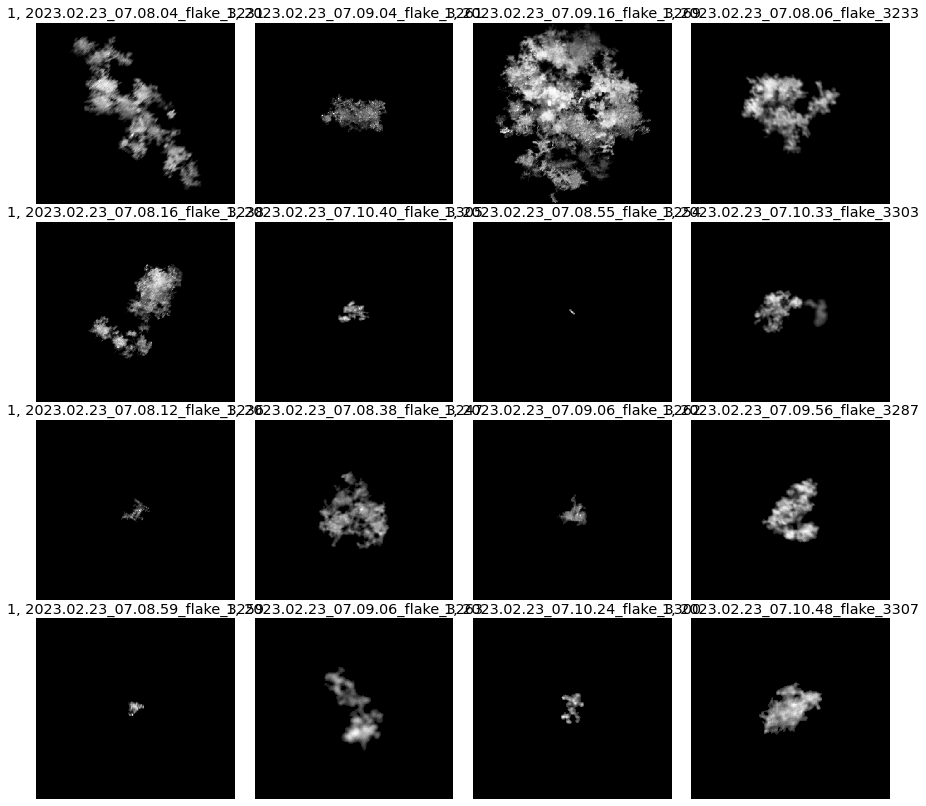

In [45]:
# plot aggregate particles in specific precipitation event
aggregate_db.plot_flakes(cam_id=1, n_images=16, col_wrap=4)
# plt.savefig(os.path.join(FIG_DIR, 'triplet_img', f'{flake_ids_aggregate[0]}_{flake_ids_aggregate[-1]}_cam1_aggregate.png'), format='png', bbox_inches='tight', dpi=300)

# aggregate_db.plot_flakes(cam_id=2, n_images=10, col_wrap=5)
# plt.savefig(os.path.join(FIG_DIR, 'triplet_img', f'{flake_ids_aggregate[0]}_{flake_ids_aggregate[-1]}_cam2_aggregate.png'), format='png', bbox_inches='tight', dpi=300)

In [46]:
if cam1.index.name == "flake_id":
    flake_ids = cam1.index[mask].tolist()
elif 'flake_id' in cam1.columns:
    flake_ids = cam1.loc[mask, 'flake_id'].tolist()
else:
    raise RuntimeError("Can't find flake_id as index or column in cam1")

if len(flake_ids) == 0:
    print("No flakes found in that time window.")
else:
    # 5) subset the MASC_DB using sel
    subset_db = campaign23.sel(flake_ids=flake_ids)   # returns a MASC_DB instance. 

    # 6) then use your arrange / plot pipeline on the subset
    largeD = subset_db.arrange('cam1.Dmax', decreasing=True)   
    largeD.plot_triplets(n_triplets=3)                         # plot_triplets 

# plt.savefig(os.path.join(FIG_DIR, 'triplet_img', '2023-03-09.png'), format='png', bbox_inches='tight', dpi=300) #transparent=True,

NameError: name 'mask' is not defined

In [ ]:
	
# Filter on quality
print("Number of flakes:", len(subset_db))
print("Filtering on average triplet image quality > 9.")
idx = subset_db.triplet["flake_quality_xhi"] > 9.0 # Average quality ind (on the three cams)| "xi" in Praz et 
subset_db = subset_db.isel(idx)

print("Number of flakes:", len(subset_db))
# # Filter on classification probability
# print("Filtering on average triplet hydrometeor classification probabiliy > 0.9")
# idx = subset_db.triplet["snowflake_class_prob"] > 0.9 # classification probability
# subset_db = subset_db.isel(idx)

# print("Number of flakes:", len(subset_db))

Number of flakes: 99
Filtering on average triplet image quality > 9.
Number of flakes: 27


In [ ]:
# df_precip = ds[ds['snowflake_class_name'] == 'graupel']
df_precip = ds.copy()
df_events = df_precip.reset_index().rename(columns={"time": "end_time"})
df_events

,end_time,snowflake_class_name_60,shifted_time_end,start_time,delta_h,rate_mm_h,snowflake_class_name_70,snowflake_class_name_80,S_0_0.0_400_mm_h
0,2023-02-19 08:27:00,mixed,2023-02-19 08:21:00,2023-02-19 08:24:00,0.050000,2.220000,mixed,mixed,inf
1,2023-02-19 08:29:00,aggregate,2023-02-19 08:23:00,2023-02-19 08:27:00,0.033333,6.663000,aggregate,aggregate,inf
2,2023-02-19 08:33:00,aggregate,2023-02-19 08:27:00,2023-02-19 08:29:00,0.066667,3.334500,aggregate,mixed,inf
3,2023-02-19 08:40:00,aggregate,2023-02-19 08:36:00,2023-02-19 08:33:00,0.116667,0.953143,mixed,mixed,inf
4,2023-02-19 09:24:00,aggregate,2023-02-19 09:21:00,2023-02-19 08:48:00,0.600000,0.185333,aggregate,aggregate,inf
...,...,...,...,...,...,...,...,...,...
531,2023-03-12 14:51:00,graupel,2023-03-12 14:48:00,2023-03-12 14:42:00,0.150000,0.889111,graupel,graupel,inf
532,2023-03-12 20:43:00,mixed,2023-03-12 20:39:00,2023-03-12 20:37:00,0.100000,1.326000,mixed,mixed,inf
533,2023-03-12 23:17:00,graupel,2023-03-12 23:11:00,2023-03-12 22:33:00,0.733333,0.180409,graupel,mixed,inf
534,2023-03-13 01:07:00,aggregate,2023-03-13 01:02:00,2023-03-13 00:56:00,0.183333,0.726545,mixed,mixed,inf


In [ ]:
slice_flake_ids_precip = []
for end_time, start_time in df_precip['start_time'].items():
    t0 = start_time
    t1 = end_time - pd.Timedelta(seconds=1)
    mask = (
        (cam1['datetime'] >= t0) &
        (cam1['datetime'] <= t1)
    )
    if cam1.index.name == "flake_id":
            flake_ids_df_precip = cam1.index[mask].tolist()
    elif 'flake_id' in cam1.columns:
            flake_ids_df_precip = cam1.loc[mask, 'flake_id'].tolist()
    else:
            raise RuntimeError("Can't find flake_id as index or column in cam1")
    slice_flake_ids_precip.extend(flake_ids_df_precip)


if len(flake_ids_df_precip) == 0:
    print("No flakes found in that time window.")
else:
    # 5) subset the MASC_DB using sel
    df_precip_db = campaign23.sel(flake_ids=slice_flake_ids_precip)   # returns a MASC_DB instance. 

In [ ]:
# df_flakes = df_precip_db.triplet.rename(columns={"index":"flake_id"})
# keep only needed columns
df_flakes = df_precip_db.triplet[["flake_id", "datetime", "flake_Dmax", "gan3d_mass"]]

In [ ]:
event_intervals = pd.IntervalIndex.from_arrays(df_events["start_time"],
                             df_events["end_time"],
                             closed="left")

In [ ]:
flake_times = df_flakes["datetime"].values
event_idx = event_intervals.get_indexer(flake_times)

In [ ]:
# keep only events that fall into events
valid = event_idx != -1
df_flakes_evt = df_flakes.loc[valid].copy()
df_flakes_evt["event_idx"] = event_idx[valid]

In [ ]:
# attach precipitation rate to each flake
df_flakes_evt["rate_mm_h"] = df_events.loc[df_flakes_evt["event_idx"], "rate_mm_h"].values

In [ ]:
df_flakes_evt["gan3d_mass"].min(), df_flakes_evt["gan3d_mass"].max()

(1.5e-08, 5.3086e-05)

In [ ]:
# define linear bins
dmin = df_flakes_evt["flake_Dmax"].min()
dmax = df_flakes_evt["flake_Dmax"].max()

d_bins = np.arange(0.0003, 0.0105, 0.0005)

rmin = df_flakes_evt["rate_mm_h"].min()
rmax = df_flakes_evt["rate_mm_h"].max()
r_bins = np.arange(0., 10, 0.5)

mmin = df_flakes_evt["gan3d_mass"].min()
mmax = df_flakes_evt["gan3d_mass"].max()
m_bins = np.linspace(mmin, mmax, 40)

In [ ]:
# 2D histogram
H, xedges, yedges = np.histogram2d(df_flakes_evt["rate_mm_h"],
                                   df_flakes_evt["flake_Dmax"],
                                   bins=[r_bins, d_bins])

In [ ]:
# H, xedges, yedges = np.histogram2d(df_flakes_evt["rate_mm_h"],
#                                    df_flakes_evt["gan3d_mass"],
#                                    bins=[r_bins, m_bins])

In [ ]:
H.max()

241.0

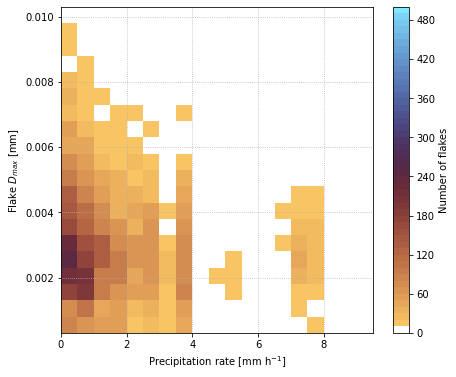

In [ ]:
levels = np.arange(0, 510, 10)
cmap = cm.managua
## extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]
# force the first color entry to be white
cmaplist[0] = (255,255,255, 0.9)
# create the new map
cmap = LinearSegmentedColormap.from_list(
    'Custom cmap', cmaplist, len(levels))
norm = BoundaryNorm(levels, cmap.N, clip=True)

fig, ax = plt.subplots(figsize=(7,6))
pcm = ax.pcolormesh(xedges, yedges, H.T, cmap=cmap, 
                    norm=norm, 
                    shading="auto")

cb = fig.colorbar(pcm, ax=ax)
cb.set_label("Number of flakes")

ax.set_xlabel("Precipitation rate [mm h$^{-1}$]")
ax.set_ylabel("Flake $D_{max}$ [mm]")

# ax.set_title("Flake size distribution vs precipitation rate")

# ax.set_xscale('log')
# ax.set_yscale('log')
# ax.set_xlim(0,10)
ax.grid(ls=":", which='both')
